<a href="https://colab.research.google.com/github/ishara2007/Machine_Learning/blob/main/07_UnsupervisedLearning_KMeansClusters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

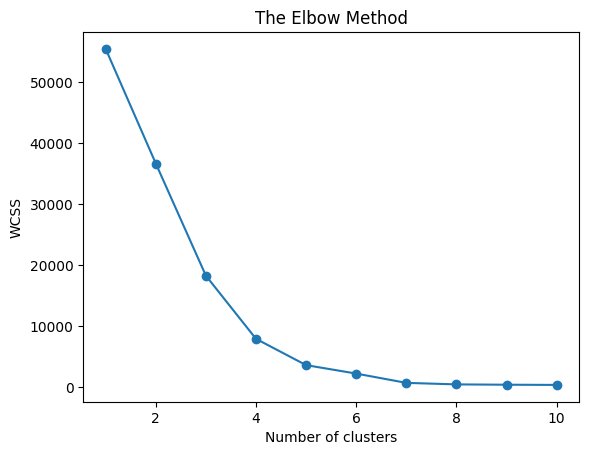

    CustomerID  AnnualIncome  SpendingScore  Cluster
0            1            15             39        6
1            2            16             81        2
2            3            17              6        5
3            4            18             77        2
4            5            19             40        6
5            6            20             76        2
6            7            21              6        5
7            8            22             94        2
8            9            23              3        5
9           10            24             72        2
10          11            40             20        0
11          12            42             25        0
12          13            43             15        0
13          14            45             18        0
14          15            46             22        0
15          16            60             55        4
16          17            62             58        4
17          18            64             60   

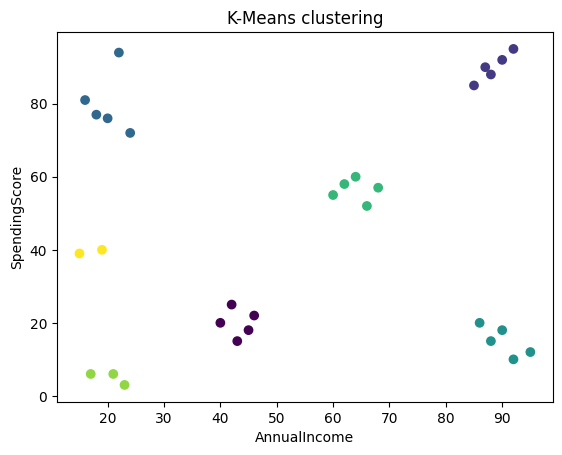

Silhouette Score:  0.8179309432490389
Model Saved Successfully


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from numpy.random.mtrand import random
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("/content/kmeans_customers.csv")

X = df[["AnnualIncome","SpendingScore"]]

wcss = []

for k in range(1, 11):
  model = KMeans(n_clusters = k, random_state = 42)
  model.fit(X)
  wcss.append(model.inertia_)

#Show the data in a pychart
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("The Elbow Method")
plt.show()

#clustering the data into "7"
model = KMeans(n_clusters = 7, random_state = 42)
df["Cluster"] = model.fit_predict(X)
print(df)

#Assiging colors in mathplotlib keyword to assign color is "c"
plt.scatter(df["AnnualIncome"], df["SpendingScore"],
c = df["Cluster"], cmap = "viridis")

plt.xlabel("AnnualIncome")
plt.ylabel("SpendingScore")
plt.title("K-Means clustering")
plt.show()

score = silhouette_score(X, df["Cluster"])
print("Silhouette Score: ", score)

#Save and download the created and trained model
joblib.dump(model, "Unsupervised Learning Model using K-Means.pkl")
print("Model Saved Successfully")

